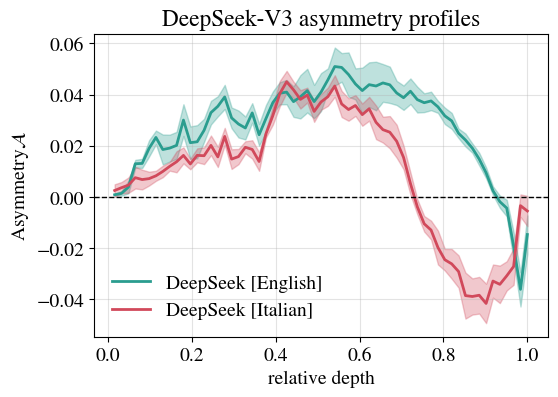

In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from cycler import cycler

# Plot style (cleaned, aligned with plot.ipynb defaults)
rcpsize = 14
plt.rcParams['xtick.labelsize'] = rcpsize
plt.rcParams['ytick.labelsize'] = rcpsize
plt.rcParams['mathtext.fontset'] = 'stix'
plt.rcParams['font.family'] = 'STIXGeneral'
plt.rcParams['font.size'] = rcpsize
plt.rcParams.update({'figure.autolayout': True})
colors = plt.style.library['seaborn-v0_8-dark-palette']['axes.prop_cycle'].by_key()['color']
plt.rcParams['axes.prop_cycle'] = cycler(color=colors)

# Data config
base = Path('results/santiago')
model = 'deepseek'
languages = ['english', 'italian']
subtract_mean = 0
batch_shuffle = 0
take_last = 1
n_files = 400
min_token_length = 40
mask = 2
k = 10
Nbits = 0
seeds = np.arange(5, dtype=int)
n_tokens = 1

def result_folder(language: str, seed: int) -> Path:
    return (
        base
        / f'subtract_mean_{subtract_mean}'
        / f'batch_shuffle_{batch_shuffle}'
        / f'take_last_{take_last}'
        / f'modelA_{model}'
        / f'modelB_{model}'
        / f'n_files_{n_files}'
        / f'min_token_length_{min_token_length}'
        / f'languageA_{language}'
        / f'mask_{mask}'
        / f'k_{k}'
        / f'Nbits_{Nbits}'
        / f'seed_{seed}'
    )

# Cute but readable pair for the two languages
language_colors = {
    'english': '#2A9D8F',
    'italian': '#D1495B',
}

fig, ax = plt.subplots(1, 1, figsize=(5.8, 4.2))

for language in languages:
    ab_list = []
    ba_list = []
    for seed in seeds:
        folder = result_folder(language, seed)
        ab_path = folder / f'n_tokens_{n_tokens}_avg_0_AB.npy'
        ba_path = folder / f'n_tokens_{n_tokens}_avg_0_BA.npy'
        if not ab_path.exists() or not ba_path.exists():
            raise FileNotFoundError(f'Missing result file in {folder}')
        ab_list.append(np.load(ab_path))
        ba_list.append(np.load(ba_path))

    ab = np.stack(ab_list, axis=0)  # [seed, layer, tau]
    ba = np.stack(ba_list, axis=0)  # [seed, layer, tau]

    # Same asymmetry as plot.ipynb
    A = (ab - ba).mean(axis=-1)  # [seed, layer]
    mu = A.mean(axis=0)
    std = A.std(axis=0)

    model_depth = A.shape[1]
    x = np.arange(1, model_depth + 1) / model_depth

    ax.plot(
        x,
        mu,
        color=language_colors[language],
        lw=2.0,
        label=f'DeepSeek [{language.title()}]',
    )
    ax.fill_between(x, mu - std, mu + std, color=language_colors[language], alpha=0.30)

ax.axhline(0.0, color='black', linestyle='--', linewidth=1.0)
ax.set_xlabel('relative depth')
ax.set_ylabel('Asymmetry' + r'$\mathcal{A}$')
ax.set_title('DeepSeek-V3 asymmetry profiles')
ax.grid(alpha=0.35)
ax.legend(frameon=False)

# fig.savefig('results/deepseek_asymmetries_english_italian.pdf', dpi=200, bbox_inches='tight')
plt.show()
